In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\daphd\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [15]:
# Stopwords (Idem que dans s1) 
#ajout des mots pour gagner en pertinence 
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem","etc","tel"]
sw = set(sw)


In [4]:
# Choisir une année
#s'assurer que les années soient présentes dans les fichiers grâce au titre de l'article 
year = 1956

In [5]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [6]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [7]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

'9 MARDI 10 JANVIER 1956 LE SOIR BOURSE D’ANVERS LUNDI j) JANVIER 1950 Tendance satisfaisante dans un marché relativement actif, mal» freiné par lea opérations de compensation. La plupart ries valeurs '

In [8]:
# Ecrire tout le contenu dans un fichier temporaire
#tmp = temporaire pour récup les mots d'une année entière pour un nuage de mots
#ensemble des articles d'une année entière dans le fichier dans l'ordi
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [9]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'9 MARDI 10 JANVIER 1956 LE SOIR BOURSE D’ANVERS LUNDI j) JANVIER 1950 Tendance satisfaisante dans un marché relativement actif, mal» freiné par lea opérations de compensation. La plupart ries valeurs te contentent de confirmer leurs cotations. Quelques unes notamment la Brazllian Traction, Kuala et Royal Dulch améliorent leur cours. Les crupl- /lércs caoutchoutlères, électricités et diverses légèrement mieux. Les banques, métallurgiques et pétrolières soutenues. Les coloniales et étrangères légè'

In [10]:
#définition d'un nom de fichier > année et nom du fichier 
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text) #plus de deux caractères, pas de mots vides 
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw] #mettre en majuscule (compréhension)
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'



In [11]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1956_clean.txt!'

In [12]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'MARDI JANVIER SOIR BOURSE ANVERS LUNDI JANVIER TENDANCE SATISFAISANTE MARCHÉ RELATIVEMENT ACTIF MAL FREINÉ LEA OPÉRATIONS COMPENSATION PLUPART RIES VALEURS CONTENTENT CONFIRMER LEURS COTATIONS QUELQUES UNES NOTAMMENT BRAZLLIAN TRACTION KUALA ROYAL DULCH AMÉLIORENT COURS CRUPL LÉRCS CAOUTCHOUTLÈRES ÉLECTRICITÉS DIVERSES LÉGÈREMENT MIEUX BANQUES MÉTALLURGIQUES PÉTROLIÈRES SOUTENUES COLONIALES ÉTRANGÈRES LÉGÈREMENT FAIBLES CLÔTURE RÉGULIÈRE BANQUES SOC PORTEFEUILLE GPTREPR IMMOBILIÈRES HYPOTH HÔTEL'

In [13]:
#élément pour lancer la projection > string pour faire un split sur l'espace après
#plus compteur 
#parcourir la liste donne une idée des mots vides à retirer dans la liste de stop words du début
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('TÉL', 2450), ('RUE', 2096), ('BRUXELLES', 1257), ('ANS', 795), ('PRIX', 721), ('TRÈS', 614), ('APP', 613), ('MAISON', 570), ('BON', 547), ('PLACE', 547)]


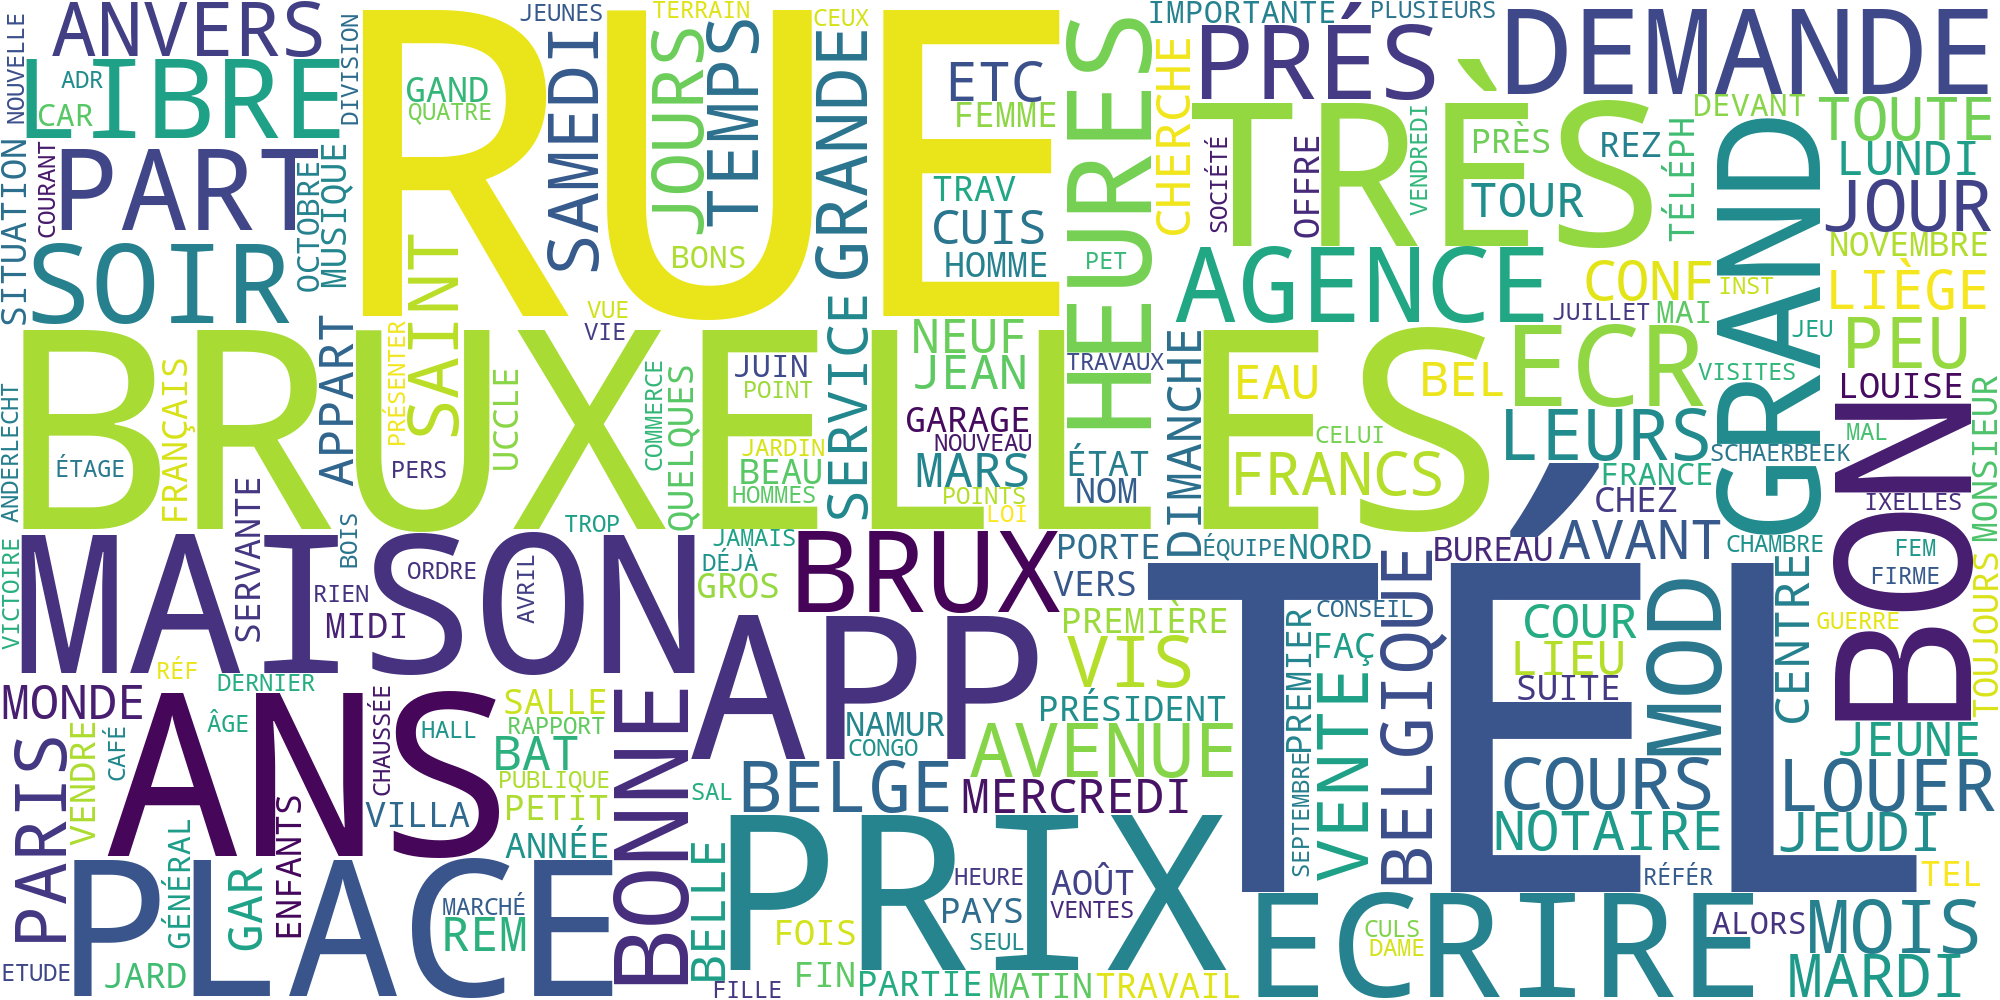

In [16]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))